Loaded image shape: (426, 639)


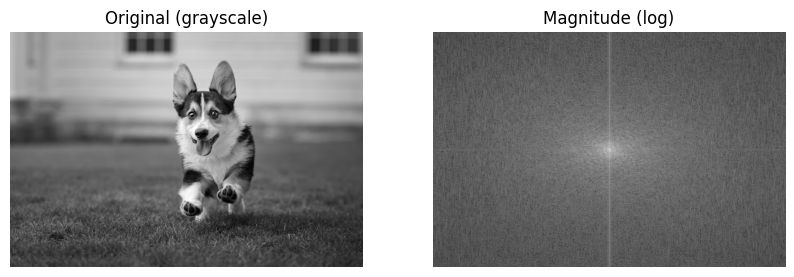

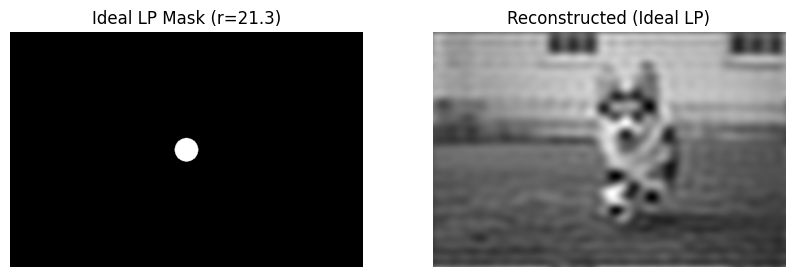

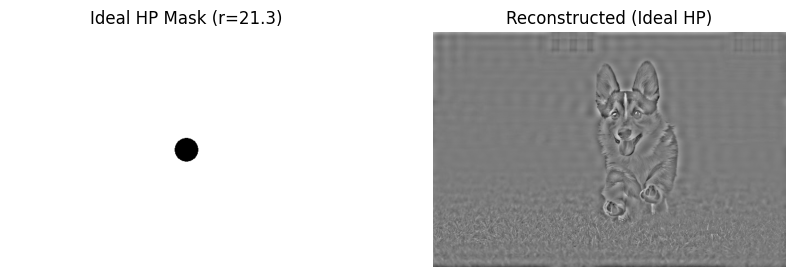

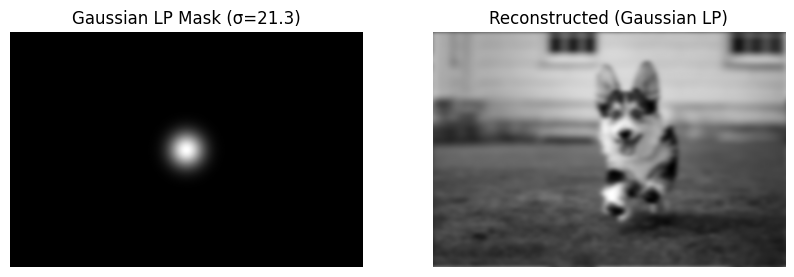

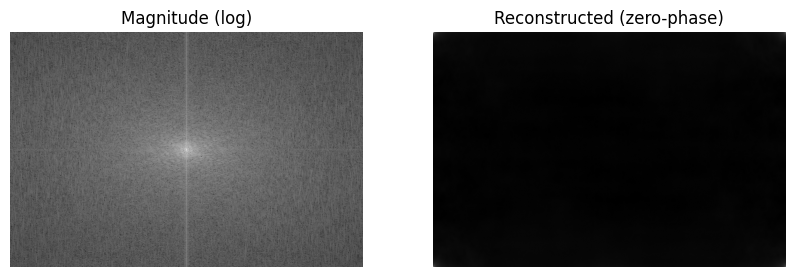

All outputs saved to: /content/output


In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from scipy import fftpack
import os

# ---- Configuration ----
INPUT_PATH = "/content/image1.jpg"        # change to your image file
OUTPUT_DIR = "/content/output"
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)


# ---- Utilities ----
def load_grayscale(path, resize_to=None):
    """Load image and convert to grayscale numpy array (float)."""
    img = Image.open(path).convert("L")
    if resize_to is not None:
        img = img.resize(resize_to, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)
    return arr

def save_image(arr, path):
    """Save a floating-point image (clipped 0..255) to disk as uint8."""
    clipped = np.clip(arr, 0, 255).astype(np.uint8)
    Image.fromarray(clipped).save(path)

def show_and_save(imgs, titles, filename=None, cmap='gray', figsize=(12,6)):
    """Simple side-by-side display and optional save of figure."""
    n = len(imgs)
    plt.figure(figsize=figsize)
    for i, (img, t) in enumerate(zip(imgs, titles), 1):
        plt.subplot(1, n, i)
        plt.imshow(img, cmap=cmap)
        plt.title(t)
        plt.axis('off')
    if filename:
        plt.savefig(os.path.join(OUTPUT_DIR, filename), bbox_inches="tight", dpi=150)
    plt.show()


# ---- FFT helpers ----
def compute_fft(image):
    """
    Compute 2D FFT and return shifted FFT, magnitude (log) and phase.
    image: 2D numpy array (grayscale).
    """
    F = np.fft.fft2(image)
    Fshift = np.fft.fftshift(F)
    magnitude = np.log1p(np.abs(Fshift))  # log for visualization
    phase = np.angle(Fshift)
    return Fshift, magnitude, phase

def compute_ifft(Fshift):
    """
    Inverse FFT from shifted frequency representation.
    Returns the real-valued spatial domain image.
    """
    F_ishift = np.fft.ifftshift(Fshift)
    img_back = np.fft.ifft2(F_ishift)
    img_back = np.real(img_back)
    return img_back

# ---- Frequency masks/filters ----
def create_distance_matrix(shape):
    """Return matrix of distances from center for given shape (rows, cols)."""
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2
    y = np.arange(rows) - crow
    x = np.arange(cols) - ccol
    X, Y = np.meshgrid(x, y)
    D = np.sqrt(X**2 + Y**2)
    return D

def ideal_lowpass(shape, radius):
    """Ideal (binary) low-pass: 1 inside radius, 0 outside."""
    D = create_distance_matrix(shape)
    mask = (D <= radius).astype(np.float32)
    return mask

def ideal_highpass(shape, radius):
    """Ideal high-pass: 1 outside radius, 0 inside."""
    return 1.0 - ideal_lowpass(shape, radius)

def gaussian_lowpass(shape, sigma):
    """Gaussian low-pass filter in frequency domain."""
    D = create_distance_matrix(shape)
    mask = np.exp(-(D**2) / (2 * (sigma**2)))
    return mask

def apply_mask(Fshift, mask):
    """Apply frequency-domain mask (same shape as Fshift)."""
    # If mask is real-valued, multiply magnitude while preserving phase
    return Fshift * mask


# ---- Example pipeline ----
def example_pipeline(input_path):
    img = load_grayscale(input_path)
    rows, cols = img.shape
    print(f"Loaded image shape: {img.shape}")

    # compute FFT
    Fshift, magnitude, phase = compute_fft(img)
    show_and_save([img, magnitude], ["Original (grayscale)", "Magnitude (log)"],
                  filename="original_and_magnitude.png", figsize=(10,5))
    save_image(img, os.path.join(OUTPUT_DIR, "original_gray.png"))

    # --- Ideal low-pass filter ---
    radius = min(rows, cols) * 0.05  # 5% of smaller dimension
    mask_ilp = ideal_lowpass((rows, cols), radius)
    F_ilp = apply_mask(Fshift, mask_ilp)
    img_ilp = compute_ifft(F_ilp)
    show_and_save([mask_ilp, img_ilp], [f"Ideal LP Mask (r={radius:.1f})", "Reconstructed (Ideal LP)"],
                  filename="ideal_lp_result.png", figsize=(10,5))
    save_image(img_ilp, os.path.join(OUTPUT_DIR, "reconstructed_ideal_lowpass.png"))

    # --- Ideal high-pass filter ---
    mask_ihp = ideal_highpass((rows, cols), radius)
    F_ihp = apply_mask(Fshift, mask_ihp)
    img_ihp = compute_ifft(F_ihp)
    show_and_save([mask_ihp, img_ihp], [f"Ideal HP Mask (r={radius:.1f})", "Reconstructed (Ideal HP)"],
                  filename="ideal_hp_result.png", figsize=(10,5))
    save_image(img_ihp, os.path.join(OUTPUT_DIR, "reconstructed_ideal_highpass.png"))

    # --- Gaussian low-pass filter ---
    sigma = min(rows, cols) * 0.05
    mask_glp = gaussian_lowpass((rows, cols), sigma)
    F_glp = apply_mask(Fshift, mask_glp)
    img_glp = compute_ifft(F_glp)
    show_and_save([mask_glp, img_glp], [f"Gaussian LP Mask (σ={sigma:.1f})", "Reconstructed (Gaussian LP)"],
                  filename="gaussian_lp_result.png", figsize=(10,5))
    save_image(img_glp, os.path.join(OUTPUT_DIR, "reconstructed_gaussian_lowpass.png"))

    # --- Optional: keep magnitude only or modify magnitude/phase ---
    # Example: zero-phase (use magnitude but set phase to zero)
    mag = np.abs(Fshift)
    zero_phase = np.zeros_like(np.angle(Fshift))
    F_zero_phase = mag * np.exp(1j * zero_phase)
    img_zero_phase = compute_ifft(F_zero_phase)
    show_and_save([magnitude, img_zero_phase], ["Magnitude (log)", "Reconstructed (zero-phase)"],
                  filename="zero_phase_result.png", figsize=(10,5))
    save_image(img_zero_phase, os.path.join(OUTPUT_DIR, "reconstructed_zero_phase.png"))

    print("All outputs saved to:", OUTPUT_DIR)


if __name__ == "__main__":
    if not os.path.exists(INPUT_PATH):
        raise FileNotFoundError(f"Input image not found: {INPUT_PATH} (change INPUT_PATH in script)")
    example_pipeline(INPUT_PATH)



Loaded image shape: (538, 960, 3)


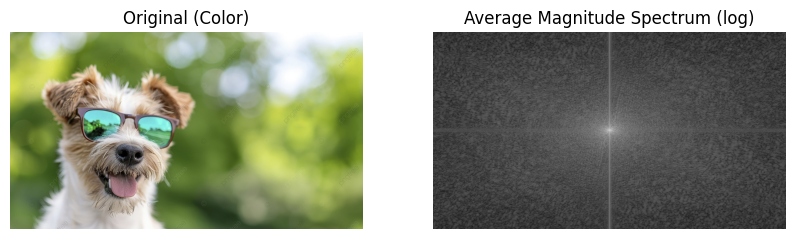

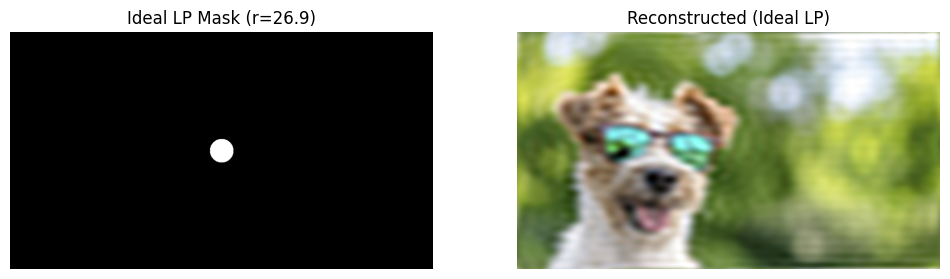

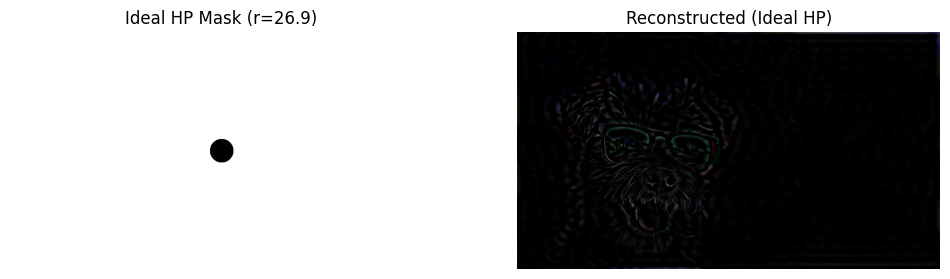

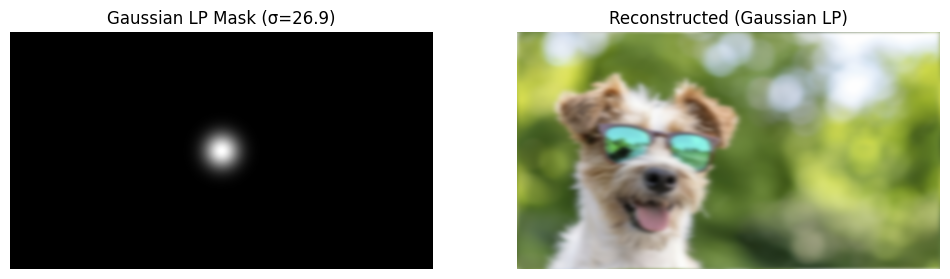

All color FFT outputs saved to: fft_color_outputs


In [3]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os

# ---- Configuration ----
INPUT_PATH = "/content/image2.jpg"      # your color image path
OUTPUT_DIR = "fft_color_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ---- Utilities ----
def load_color(path, resize_to=None):
    """Load color image (RGB) as float32 numpy array in [0,255]."""
    img = Image.open(path).convert("RGB")
    if resize_to is not None:
        img = img.resize(resize_to, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)
    return arr

def save_image(arr, path):
    """Save a floating-point RGB image (clipped 0..255)."""
    clipped = np.clip(arr, 0, 255).astype(np.uint8)
    Image.fromarray(clipped).save(path)

def show_and_save(imgs, titles, filename=None, figsize=(12,6)):
    n = len(imgs)
    plt.figure(figsize=figsize)
    for i, (img, t) in enumerate(zip(imgs, titles), 1):
        plt.subplot(1, n, i)
        if img.ndim == 2:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(np.clip(img / 255.0, 0, 1))
        plt.title(t)
        plt.axis('off')
    if filename:
        plt.savefig(os.path.join(OUTPUT_DIR, filename), bbox_inches="tight", dpi=150)
    plt.show()


# ---- FFT helpers ----
def compute_fft_channelwise(img):
    """Compute FFT for each channel (RGB)."""
    Fshift_channels = []
    for c in range(3):
        F = np.fft.fft2(img[..., c])
        Fshift = np.fft.fftshift(F)
        Fshift_channels.append(Fshift)
    return Fshift_channels

def compute_ifft_channelwise(Fshift_channels):
    """Inverse FFT from list of Fshift per channel."""
    rec_channels = []
    for Fshift in Fshift_channels:
        F_ishift = np.fft.ifftshift(Fshift)
        img_back = np.real(np.fft.ifft2(F_ishift))
        rec_channels.append(img_back)
    reconstructed = np.stack(rec_channels, axis=-1)
    return reconstructed


# ---- Frequency filters ----
def create_distance_matrix(shape):
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2
    y = np.arange(rows) - crow
    x = np.arange(cols) - ccol
    X, Y = np.meshgrid(x, y)
    D = np.sqrt(X**2 + Y**2)
    return D

def ideal_lowpass(shape, radius):
    D = create_distance_matrix(shape)
    return (D <= radius).astype(np.float32)

def ideal_highpass(shape, radius):
    return 1.0 - ideal_lowpass(shape, radius)

def gaussian_lowpass(shape, sigma):
    D = create_distance_matrix(shape)
    return np.exp(-(D**2) / (2 * (sigma**2)))

def apply_mask_channels(Fshift_channels, mask):
    masked = [Fshift * mask for Fshift in Fshift_channels]
    return masked


# ---- Pipeline ----
def example_pipeline_color(input_path):
    img = load_color(input_path)
    rows, cols, _ = img.shape
    print(f"Loaded image shape: {img.shape}")

    # Compute FFT per channel
    Fshift_channels = compute_fft_channelwise(img)

    # Magnitude spectra (average over RGB)
    magnitude = np.mean([np.log1p(np.abs(F)) for F in Fshift_channels], axis=0)
    show_and_save([img, magnitude], ["Original (Color)", "Average Magnitude Spectrum (log)"],
                  filename="color_magnitude.png", figsize=(10,5))
    save_image(img, os.path.join(OUTPUT_DIR, "original_color.png"))

    # --- Ideal Low-Pass Filter ---
    radius = min(rows, cols) * 0.05
    mask_ilp = ideal_lowpass((rows, cols), radius)
    F_ilp_channels = apply_mask_channels(Fshift_channels, mask_ilp)
    img_ilp = compute_ifft_channelwise(F_ilp_channels)
    show_and_save([mask_ilp, img_ilp], [f"Ideal LP Mask (r={radius:.1f})", "Reconstructed (Ideal LP)"],
                  filename="ideal_lp_color.png")
    save_image(img_ilp, os.path.join(OUTPUT_DIR, "reconstructed_ideal_lowpass_color.png"))

    # --- Ideal High-Pass Filter ---
    mask_ihp = ideal_highpass((rows, cols), radius)
    F_ihp_channels = apply_mask_channels(Fshift_channels, mask_ihp)
    img_ihp = compute_ifft_channelwise(F_ihp_channels)
    show_and_save([mask_ihp, img_ihp], [f"Ideal HP Mask (r={radius:.1f})", "Reconstructed (Ideal HP)"],
                  filename="ideal_hp_color.png")
    save_image(img_ihp, os.path.join(OUTPUT_DIR, "reconstructed_ideal_highpass_color.png"))

    # --- Gaussian Low-Pass Filter ---
    sigma = min(rows, cols) * 0.05
    mask_glp = gaussian_lowpass((rows, cols), sigma)
    F_glp_channels = apply_mask_channels(Fshift_channels, mask_glp)
    img_glp = compute_ifft_channelwise(F_glp_channels)
    show_and_save([mask_glp, img_glp], [f"Gaussian LP Mask (σ={sigma:.1f})", "Reconstructed (Gaussian LP)"],
                  filename="gaussian_lp_color.png")
    save_image(img_glp, os.path.join(OUTPUT_DIR, "reconstructed_gaussian_lowpass_color.png"))

    print("All color FFT outputs saved to:", OUTPUT_DIR)


if __name__ == "__main__":
    if not os.path.exists(INPUT_PATH):
        raise FileNotFoundError(f"Image not found: {INPUT_PATH} (update INPUT_PATH)")
    example_pipeline_color(INPUT_PATH)

